In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_critics as ec

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])

[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

In [2]:
ALPHA = 0.029
sarsa_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/five_seeds"            # final health-score SARSA critics (early stopped), seeds 0-4
sarsa_terminal_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/terminal_only/five_seeds"   # final terminal-reward SARSA critics (early stopped), seeds 0-4
cql_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep"              # alpha sweep folder, as in the WIS notebook
critics_dir = "/home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response"
os.makedirs(critics_dir, exist_ok=True)

is_alpha = lambda r: np.isclose(float(r.get("cql_alpha")), ALPHA)
sarsa_models = M.load_study_models(R.make_study(sarsa_dir, family="sarsa"))
sarsa_terminal_models = M.load_study_models(R.make_study(sarsa_terminal_dir, family="sarsa"))
cql_models = M.load_study_models(R.make_study(cql_dir, family="cql", group_by=("cql_alpha",), include=is_alpha))
store = D.DataStore(keep=("val", "test"))

  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/five_seeds:
    vaso_reward_coefficient: saved=0.01 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: critic)
  loaded LoadedModel(seed 1: critic)
  loaded LoadedModel(seed 2: critic)
  loaded LoadedModel(seed 3: critic)
  loaded LoadedModel(seed 4: critic)
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/terminal_only/five_seeds:
    vaso_reward_coefficient: saved=0.2 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: critic)
  loaded LoadedModel(seed 1: critic)
  loaded LoadedModel(seed 2: critic)
  loaded LoadedModel(s

In [3]:
critics = {"SARSA health score": sarsa_models,
           "SARSA terminal": sarsa_terminal_models,
           "CQL health score": cql_models}
res = ec.dose_response(critics, store, ref="SARSA health score", split="test", dim=0)
ec.summarize_shapes(res)

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 0: 116662 rows, 3 critics
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 1: 116662 rows, 3 critics
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749

health_score      n     lower                      \
                                 range  first      mean       min       max   
critic             bin                                                        
CQL health score   0    11.85 to 70.07  23333  0.049749  0.029872  0.063772   
                   1    70.07 to 76.19  23332  0.242774  0.192911  0.300017   
                   2    76.19 to 81.23  23332  0.524199  0.428253  0.607578   
                   3    81.23 to 85.52  23332  0.670195  0.542945  0.785188   
                   4    85.52 to 94.78  23333  0.791403  0.610852  0.899627   
SARSA health score 0    11.85 to 70.07  23333  0.574868  0.520807  0.602966   
                   1    70.07 to 76.19  23332  0.983722  0.979727  0.987999   
                   2    76.19 to 81.23  23332  0.999143  0.998200  0.999871   
                   3    81.23 to 85.52  23332  0.999923  0.999871  0.999957   
                   4    85.52 to 94.78  23333  1.000000  1.000000  1.000000   
SARSA terminal     0    11.85 to 70.07  23333  0.212060  0.036986  0.599323   
                   1    70.07 to 76.19  23332  0.575261  0.230970  0.964555   
                   2    76.19 to 81.23  23332  0.877010  0.715069  0.996443   
                   3    81.23 to 85.52  23332  0.967744  0.914538  0.999143   
                   4    85.52 to 94.78  23333  0.993443  0.984743  1.000000   

                        interior                        higher            \
                            mean       min       max      mean       min   
critic             bin                                                     
CQL health score   0    0.396511  0.357305  0.459435  0.542879  0.459178   
                   1    0.250746  0.224456  0.279187  0.440485  0.378236   
                   2    0.156326  0.130165  0.187939  0.230147  0.179753   
                   3    0.091471  0.064289  0.119835  0.162361  0.096734   
                   4    0.053418  0.027129  0.084087  0.101864  0.042815   
SARSA health score 0    0.050949  0.040629  0.068358  0.368217  0.324819   
                   1    0.005263  0.003729  0.007200  0.010183  0.006000   
                   2    0.000326  0.000043  0.000600  0.000480  0.000086   
                   3    0.000051  0.000000  0.000086  0.000026  0.000000   
                   4    0.000000  0.000000  0.000000  0.000000  0.000000   
SARSA terminal     0    0.000017  0.000000  0.000043  0.491278  0.152145   
                   1    0.000000  0.000000  0.000000  0.072184  0.000386   
                   2    0.000009  0.000000  0.000043  0.016621  0.000257   
                   3    0.000000  0.000000  0.000000  0.003420  0.000086   
                   4    0.000000  0.000000  0.000000  0.000180  0.000000   

                                 irregular                          flat  \
                             max      mean       min       max      mean   
critic             bin                                                     
CQL health score   0    0.599580  0.004783  0.000300  0.013414  0.006077   
                   1    0.522758  0.006352  0.000686  0.014101  0.059643   
                   2    0.288488  0.005760  0.000129  0.013758  0.083568   
                   3    0.246528  0.004200  0.000000  0.013286  0.071773   
                   4    0.216089  0.001869  0.000000  0.006214  0.051446   
SARSA health score 0    0.420263  0.004397  0.003257  0.005786  0.001569   
                   1    0.013929  0.000437  0.000171  0.000857  0.000394   
                   2    0.001243  0.000051  0.000000  0.000086  0.000000   
                   3    0.000043  0.000000  0.000000  0.000000  0.000000   
                   4    0.000000  0.000000  0.000000  0.000000  0.000000   
SARSA terminal     0    0.702739  0.000000  0.000000  0.000000  0.296644   
                   1    0.145808  0.000000  0.000000  0.000000  0.352554   
                   2    0.029187  0.000000  0.000000  0.000000  0.106360   
                  

Saved to /home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response/dose_response_test.png
Saved to /home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response/shape_fractions_test.png


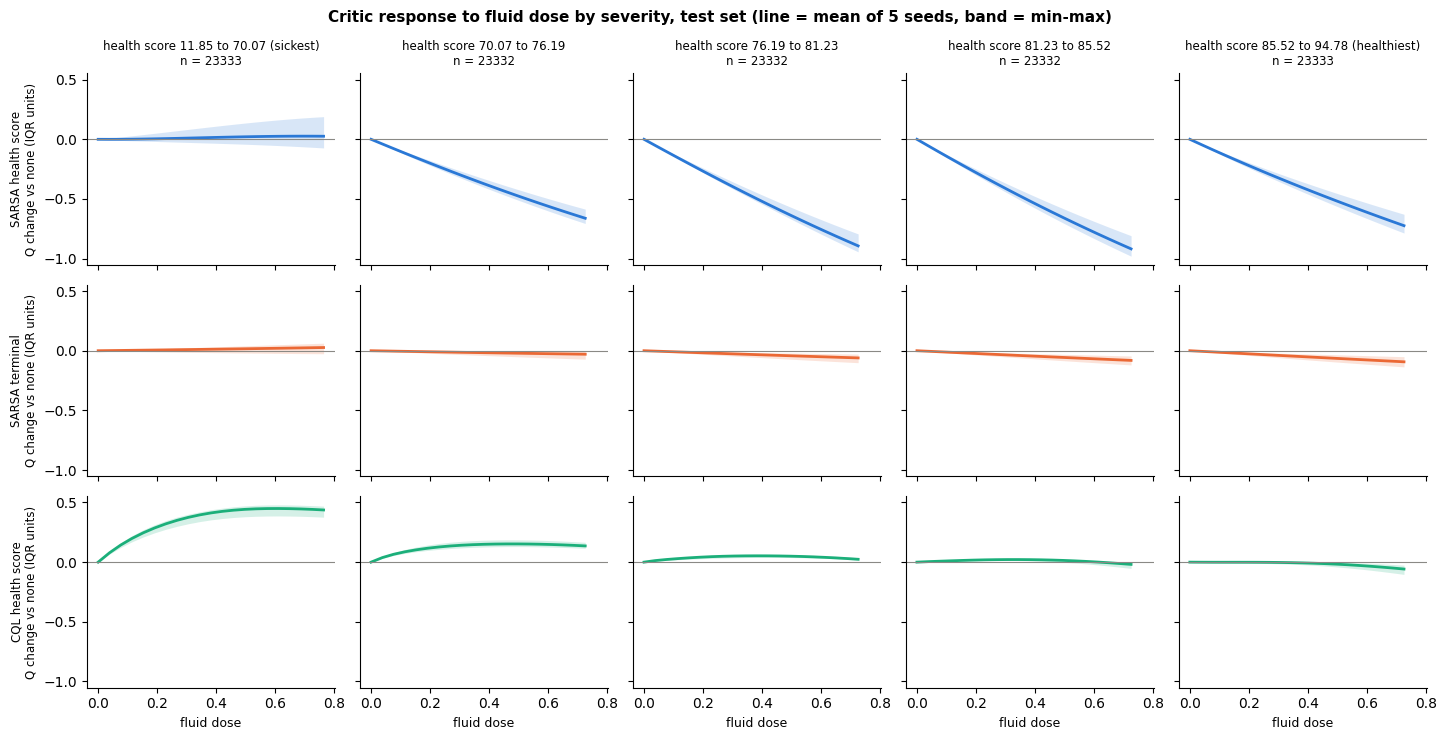

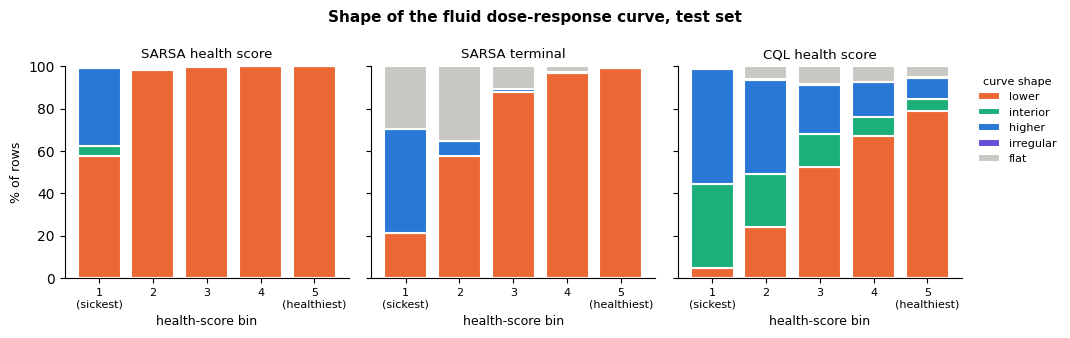

In [7]:
ec.plot_dose_response(res, save_path=os.path.join(critics_dir, "dose_response_test.png"))
ec.plot_shape_fractions(res, save_path=os.path.join(critics_dir, "shape_fractions_test.png"));

In [10]:
res.support

array([0.76319242, 0.72947007, 0.73033047, 0.7461732 , 0.7443282 ])

In [9]:
res.shapes.pivot_table(index=["critic", "bin"], columns="seed", values="delta_top")

seed                           0         1         2         3         4
critic             bin                                                  
CQL health score   0    0.377091  0.451569  0.426804  0.469642  0.461319
                   1    0.120230  0.124462  0.116039  0.153008  0.166154
                   2    0.024608  0.021099  0.019807  0.037612  0.016595
                   3   -0.011682 -0.014922 -0.005315 -0.010592 -0.052613
                   4   -0.049925 -0.058378 -0.025230 -0.052737 -0.102654
SARSA health score 0   -0.072350 -0.015474  0.041987 -0.015594  0.189880
                   1   -0.697204 -0.705559 -0.585331 -0.677095 -0.643576
                   2   -0.898595 -0.901165 -0.793127 -0.930962 -0.943213
                   3   -0.942541 -0.891344 -0.807964 -0.979715 -0.970317
                   4   -0.738108 -0.701625 -0.628324 -0.785698 -0.766351
SARSA terminal     0    0.036367 -0.025417  0.063222  0.022689  0.036502
                   1   -0.019355 -0.070776 -0.002377 -0.029822 -0.024764
                   2   -0.057924 -0.100394 -0.028268 -0.067198 -0.047711
                   3   -0.087901 -0.119138 -0.044303 -0.092703 -0.061920
                   4   -0.102757 -0.135418 -0.050040 -0.109580 -0.067066

In [11]:
obs = ec.observed_by_dose(res, critics, store, names=["SARSA health score", "SARSA terminal"], ref="SARSA health score")
ec.summarize_observed(obs)

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
  seed 0: observed returns for 2 critics
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
  seed 1: observed returns for 2 critics
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_

dose       n  n_zero       diff         lo  \
critic             bin group                                                   
SARSA health score 0   1      0.433075  4823.0   197.0   0.231431  -3.467531   
                       2      0.559523  7210.0   197.0  -0.759743  -4.969627   
                       3      0.657304  7434.0   197.0  -0.433164  -5.386400   
                   1   1      0.410811  7456.0   519.0  -1.275454  -2.646718   
                       2      0.559562  6178.0   519.0  -1.386243  -2.923910   
                       3      0.645408  5522.0   519.0  -0.982301  -2.396544   
                   2   1      0.378671  5944.0   921.0  -0.447675  -1.447387   
                       2      0.559591  5049.0   921.0  -0.292237  -1.413976   
                       3      0.646275  4733.0   921.0  -0.406368  -1.407321   
                   3   1      0.353609  3739.0  1136.0   0.161154  -0.671555   
                       2      0.563960  3675.0  1136.0   0.428161  -0.420718   
                       3      0.652164  4253.0  1136.0  -0.052900  -0.857015   
                   4   1      0.331192  2655.0  1550.0  -0.128064  -0.569989   
                       2      0.561314  2501.0  1550.0  -0.835527  -1.412474   
                       3      0.654586  2681.0  1550.0  -0.929152  -1.429342   
SARSA terminal     0   1      0.433075  4823.0   197.0 -22.419140 -45.208801   
                       2      0.559523  7210.0   197.0 -36.386532 -54.483930   
                       3      0.657304  7434.0   197.0 -21.561230 -36.015460   
                   1   1      0.410811  7456.0   519.0   0.064121  -9.468405   
                       2      0.559562  6178.0   519.0  -5.202522 -18.333697   
                       3      0.645408  5522.0   519.0   6.248683  -1.517307   
                   2   1      0.378671  5944.0   921.0  -4.517008 -14.514327   
                       2      0.559591  5049.0   921.0  -7.734239 -19.893218   
                       3      0.646275  4733.0   921.0  -4.263242 -12.216493   
                   3   1      0.353609  3739.0  1136.0  -4.499955 -10.248713   
                       2      0.563960  3675.0  1136.0  -1.643833  -7.020515   
                       3      0.652164  4253.0  1136.0  -5.855819 -11.336689   
                   4   1      0.331192  2655.0  1550.0  -1.513851  -6.502456   
                       2      0.561314  2501.0  1550.0  -1.795677  -8.462033   
                       3      0.654586  2681.0  1550.0  -7.770855 -14.996206   

                                     hi   raw_diff   diff_min   diff_max  
critic             bin group                                              
SARSA health score 0   1       4.820471  -0.462755   0.221081   0.246854  
                       2       3.814227  -1.424904  -0.810374  -0.725767  
                       3       4.752843  -1.243074  -0.462031  -0.413793  
                   1   1      -0.118813  -1.130218  -1.360453  -1.218415  
                       2       0.049310  -1.230334  -1.478626  -1.324249  
                       3       0.371329  -0.827868  -1.047763  -0.938371  
                   2   1       0.526461  -0.332088  -0.477509  -0.427654  
                       2       0.714463  -0.169751  -0.311712  -0.279168  
                       3       0.631374  -0.298727  -0.433449  -0.388195  
                   3   1       0.983295   0.206730   0.153947   0.171894  
                       2       1.248466   0.428446   0.409013   0.456694  
                       3       0.811401  -0.075173  -0.056426  -0.050534  
                   4   1       0.361988   0.078474  -0.136599  -0.122337  
                       2      -0.289745  -0.556821  -0.891209  -0.798162  
                       3      -0.374699  -0.680273  -0.991073  -0.887599  
SARSA terminal     0   1       4.503936 -24.767492 -23.056148 -21.603827  
                       2     -12.176399 -38.633276 -37.420403 -35.063269  
                       3       0.070965 -24.4103

Saved to /home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response/dose_response_observed_test.png


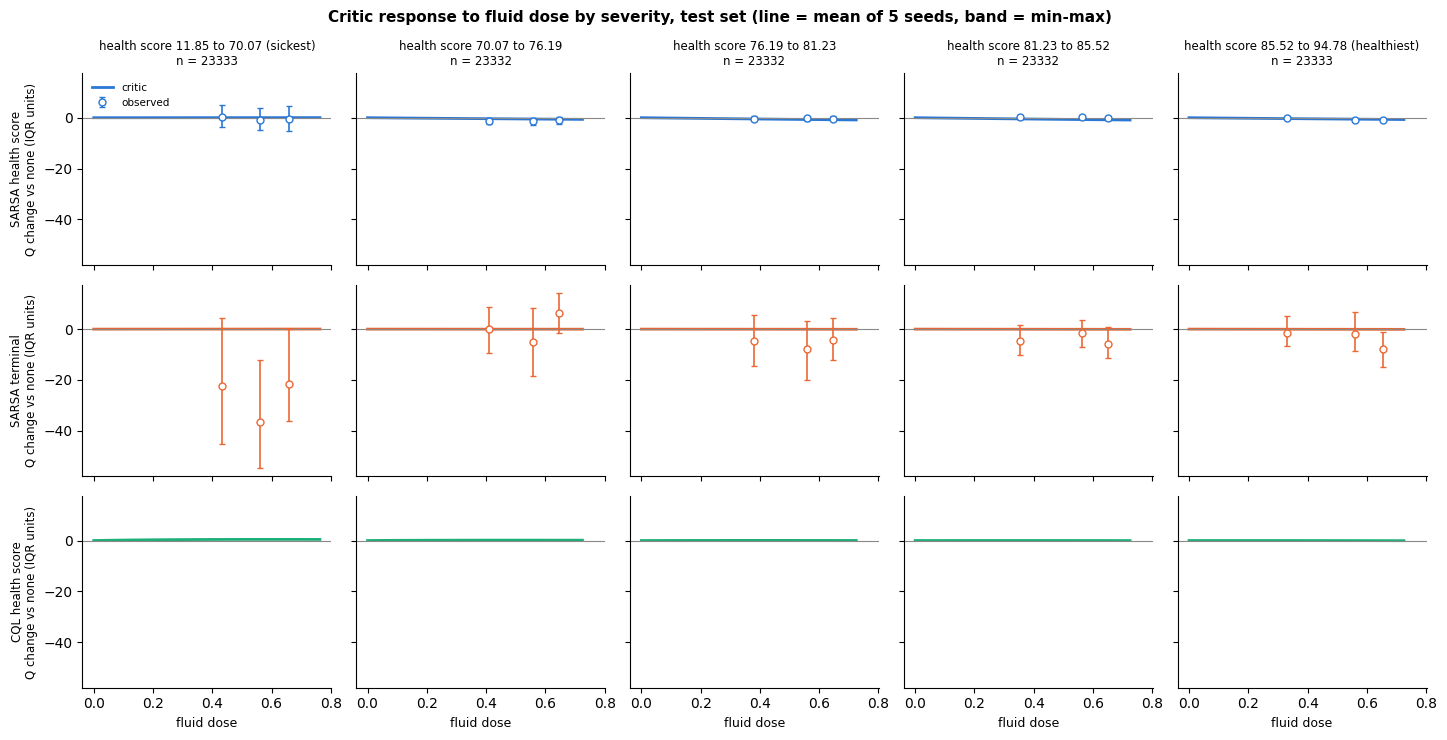

In [12]:
ec.plot_dose_response(res, observed=obs, save_path=os.path.join(critics_dir, "dose_response_observed_test.png"));